# 02. Philippine Baseline LSTM

This notebook prepares the Philippine pond dataset for the **Philippine-only LSTM baseline**.

The goal of this notebook is to build a local-data baseline that can later be compared fairly with the transfer-learning model.

**Important:** These initial cells only load and inspect `PH_data.csv`. No cleaning, resampling, scaling, sequence generation, or modeling decision is made until the actual Philippine dataset structure is confirmed.

## 1. Import the Libraries

Keras 3 is configured to use the PyTorch backend. TensorFlow is not used in the final implementation.

In [2]:
import os

os.environ["KERAS_BACKEND"] = "torch"

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import keras
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

## 2. Reproducibility Seed

The same random seed used during source-model experimentation is set here for reproducibility.

In [3]:
RANDOM_SEED = 42
keras.utils.set_random_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


## 3. Locate the Philippine Dataset

The Philippine dataset is expected at:

`../data/PH_data.csv`

The cell below checks whether the file exists before loading it.

In [4]:
PH_DATA_PATH = Path("../data/PH_data.csv")

print("Dataset path:", PH_DATA_PATH)
print("Absolute path:", PH_DATA_PATH.resolve())
print("File exists:", PH_DATA_PATH.exists())

if not PH_DATA_PATH.exists():
    raise FileNotFoundError(
        "PH_data.csv was not found. Put it inside the project's data folder."
    )

Dataset path: ..\data\PH_data.csv
Absolute path: C:\Users\Admin\Datas\PondPredict\data\PH_data.csv
File exists: True


## 4. Load the Philippine Dataset

The original CSV is loaded into a pandas DataFrame named `ph_df`.

No columns are removed or modified at this stage.

In [5]:
ph_df = pd.read_csv(PH_DATA_PATH)

print("Philippine dataset loaded successfully.")
print("Rows:", len(ph_df))
print("Columns:", len(ph_df.columns))

Philippine dataset loaded successfully.
Rows: 288
Columns: 3


## 5. Inspect Columns and Data Types

The dataset structure is inspected before deciding which columns correspond to timestamp, pH, and water temperature.

In [6]:
print("Column names:")
print(ph_df.columns.tolist())

print("\nDataset information:")
ph_df.info()

Column names:
['Date & Time', 'pH', 'Water Temp (°C)']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 288 entries, 0 to 287
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date & Time      288 non-null    str    
 1   pH               288 non-null    float64
 2   Water Temp (°C)  288 non-null    float64
dtypes: float64(2), str(1)
memory usage: 6.9 KB


## 6. Preview the First Records

In [7]:
ph_df.head(10)

,Date & Time,pH,Water Temp (°C)
0,2026-09-22 0:00,7.68,29.3
1,2026-09-22 1:00,7.65,29.1
2,2026-09-22 2:00,7.63,29.0
3,2026-09-22 3:00,7.62,28.8
4,2026-09-22 4:00,7.61,28.6
5,2026-09-22 5:00,7.62,28.4
6,2026-09-22 6:00,7.63,28.6
7,2026-09-22 7:00,7.65,28.9
8,2026-09-22 8:00,7.68,29.3
9,2026-09-22 9:00,7.71,30.0


## 7. Check Missing Values

Missing values are counted for every column. No rows are removed yet.

In [8]:
missing_values = ph_df.isnull().sum()
missing_percent = (ph_df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent
})

missing_summary

,Missing Values,Missing Percentage
Date & Time,0,0.0
pH,0,0.0
Water Temp (°C),0,0.0


## 8. Check Duplicate Rows

This checks complete duplicated rows only. Timestamp duplicates will be examined separately after the timestamp column is identified.

In [9]:
duplicate_rows = ph_df.duplicated().sum()

print("Complete duplicate rows:", duplicate_rows)

Complete duplicate rows: 0


## 9. Numerical Summary

The numerical columns are summarized without altering the dataset.

In [10]:
ph_df.describe(include="all").transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date & Time,288,288,2026-09-22 0:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pH,288.0,NaN,NaN,NaN,7.730313,0.093053,7.58,7.65,7.73,7.8,8.06
Water Temp (°C),288.0,NaN,NaN,NaN,30.594792,1.7097,28.2,29.075,30.1,32.2,33.7


## 10. Inspect Text / Object Columns

This helps identify possible date/time columns without automatically converting anything.

In [11]:
object_columns = ph_df.select_dtypes(include=["object", "string"]).columns.tolist()

print("Text/object columns:", object_columns)

for column in object_columns:
    print(f"\nColumn: {column}")
    print(ph_df[column].dropna().head(10).tolist())

Text/object columns: ['Date & Time']

Column: Date & Time
['2026-09-22 0:00', '2026-09-22 1:00', '2026-09-22 2:00', '2026-09-22 3:00', '2026-09-22 4:00', '2026-09-22 5:00', '2026-09-22 6:00', '2026-09-22 7:00', '2026-09-22 8:00', '2026-09-22 9:00']


## 11. Create the Philippine Working DataFrame

A separate working DataFrame is created from the original Philippine dataset.

The original `ph_df` remains unchanged. Column names are standardized to match the source-model terminology:

- `Date & Time` → `created_date`
- `pH` → `water_pH`
- `Water Temp (°C)` → `water_temp`

In [12]:
ph_work = ph_df.copy()

ph_work = ph_work.rename(columns={
    "Date & Time": "created_date",
    "pH": "water_pH",
    "Water Temp (°C)": "water_temp"
})

print(ph_work.columns.tolist())

ph_work.head()

['created_date', 'water_pH', 'water_temp']


,created_date,water_pH,water_temp
0,2026-09-22 0:00,7.68,29.3
1,2026-09-22 1:00,7.65,29.1
2,2026-09-22 2:00,7.63,29.0
3,2026-09-22 3:00,7.62,28.8
4,2026-09-22 4:00,7.61,28.6


## 12. Convert the Philippine Timestamp

The `created_date` column is converted from text into pandas datetime format so that chronological ordering and time-gap analysis can be performed.

In [13]:
ph_work["created_date"] = pd.to_datetime(
    ph_work["created_date"],
    format="%Y-%m-%d %H:%M"
)

print(ph_work["created_date"].dtype)

ph_work.head()

datetime64[us]


,created_date,water_pH,water_temp
0,2026-09-22 00:00:00,7.68,29.3
1,2026-09-22 01:00:00,7.65,29.1
2,2026-09-22 02:00:00,7.63,29.0
3,2026-09-22 03:00:00,7.62,28.8
4,2026-09-22 04:00:00,7.61,28.6


In [14]:
ph_work = (
    ph_work
    .sort_values("created_date")
    .reset_index(drop=True)
)

print("First timestamp:", ph_work["created_date"].min())
print("Last timestamp:", ph_work["created_date"].max())
print("Total rows:", len(ph_work))

First timestamp: 2026-09-22 00:00:00
Last timestamp: 2026-10-03 23:00:00
Total rows: 288


## 14. Check Duplicate Timestamps

Duplicate timestamps are checked separately because different sensor readings may still share the same recorded time even when complete rows are not duplicated.

In [15]:
duplicate_timestamps = ph_work["created_date"].duplicated().sum()

print("Duplicate timestamps:", duplicate_timestamps)

Duplicate timestamps: 0


## 15. Philippine Time-Interval Analysis

The difference between consecutive timestamps is calculated to verify whether the Philippine dataset contains continuous hourly observations.

In [16]:
ph_work["time_difference"] = (
    ph_work["created_date"].diff()
)

print("Most common time differences:")
print(
    ph_work["time_difference"]
    .value_counts()
    .head(10)
)

Most common time differences:
time_difference
0 days 01:00:00    287
Name: count, dtype: int64


In [17]:
print(
    "Minimum time difference:",
    ph_work["time_difference"].min()
)

print(
    "Maximum time difference:",
    ph_work["time_difference"].max()
)

print(
    "Median time difference:",
    ph_work["time_difference"].median()
)

Minimum time difference: 0 days 01:00:00
Maximum time difference: 0 days 01:00:00
Median time difference: 0 days 01:00:00


In [18]:
non_hourly_gaps = ph_work[
    ph_work["time_difference"] != pd.Timedelta(hours=1)
].copy()

# The first row naturally has NaT because there is no previous timestamp.
non_hourly_gaps = non_hourly_gaps[
    non_hourly_gaps["time_difference"].notna()
]

print("Number of non-hourly gaps:", len(non_hourly_gaps))

non_hourly_gaps[
    ["created_date", "time_difference"]
].head(20)

Number of non-hourly gaps: 0


,created_date,time_difference


## 17. Philippine Modeling-Variable Summary

The Philippine pH and water-temperature variables are summarized before model preparation.

In [19]:
ph_work[
    ["water_pH", "water_temp"]
].describe()

,water_pH,water_temp
count,288.000000,288.000000
mean,7.730313,30.594792
std,0.093053,1.709700
min,7.580000,28.200000
25%,7.650000,29.075000
50%,7.730000,30.100000
75%,7.800000,32.200000
max,8.060000,33.700000


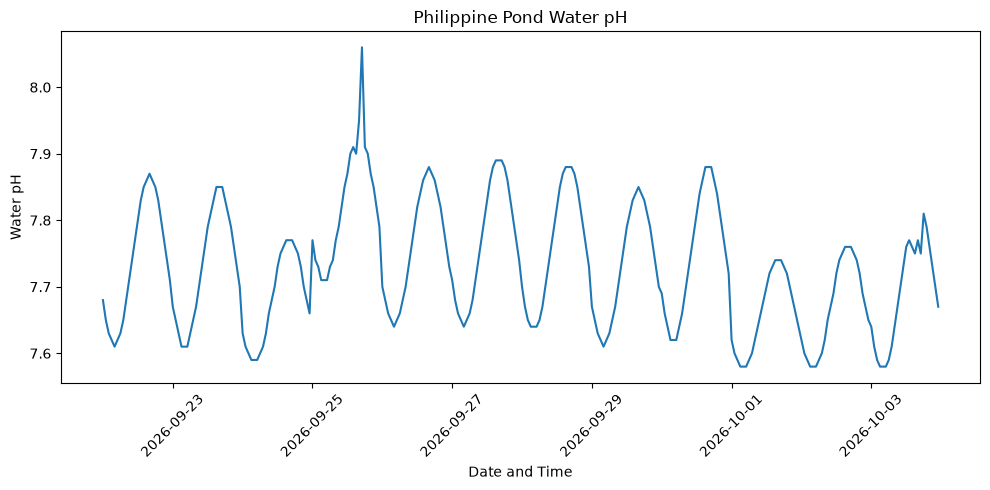

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    ph_work["created_date"],
    ph_work["water_pH"]
)

plt.xlabel("Date and Time")
plt.ylabel("Water pH")
plt.title("Philippine Pond Water pH")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

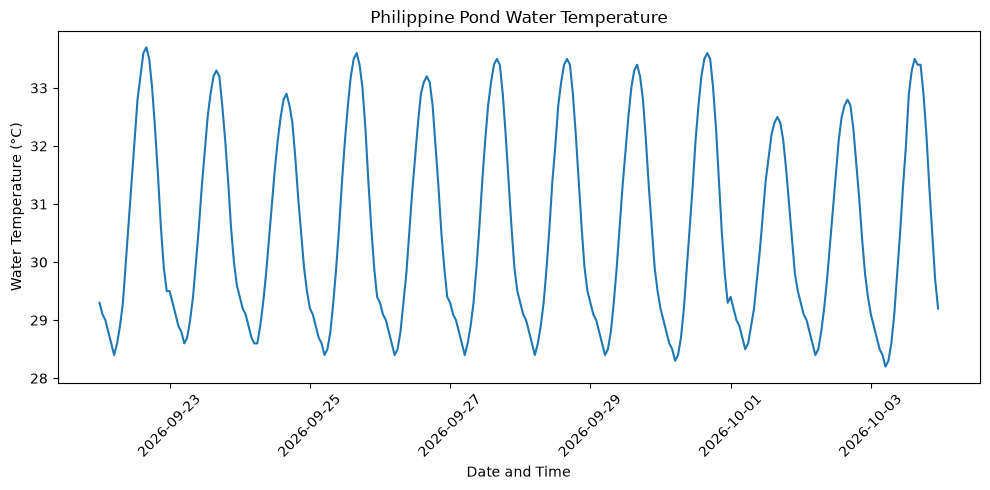

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    ph_work["created_date"],
    ph_work["water_temp"]
)

plt.xlabel("Date and Time")
plt.ylabel("Water Temperature (°C)")
plt.title("Philippine Pond Water Temperature")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 20. Initial Outlier Inspection

Boxplots are used to visually inspect the Philippine pH and water-temperature distributions before model preparation.

Potential statistical outliers are not automatically removed. Any identified values will first be examined in temporal context.

C:\Users\Admin\AppData\Local\Temp\ipykernel_10304\1428090991.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


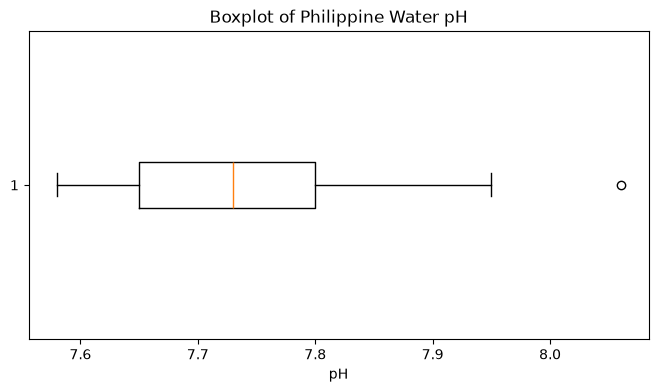

In [22]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    ph_work["water_pH"],
    vert=False
)

plt.xlabel("pH")
plt.title("Boxplot of Philippine Water pH")

plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_10304\55915281.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


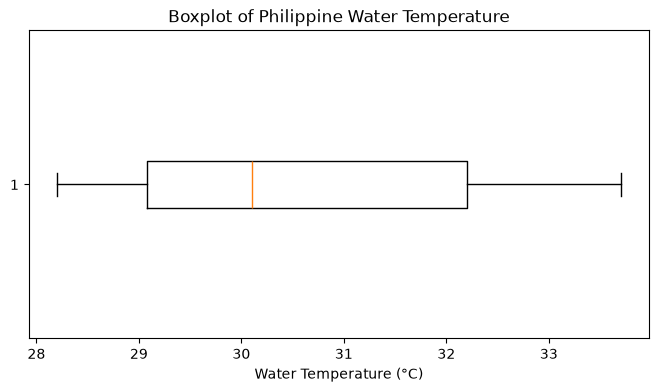

In [23]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    ph_work["water_temp"],
    vert=False
)

plt.xlabel("Water Temperature (°C)")
plt.title("Boxplot of Philippine Water Temperature")

plt.show()

## 21. IQR Outlier Assessment

The interquartile range (IQR) method is used to identify potential statistical outliers in Philippine water pH and water temperature.

Values identified by the IQR method are not automatically removed. Potential outliers are first inspected together with their timestamps and neighboring observations.

In [24]:
def check_iqr_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outliers = data[
        (data[column] < lower_bound)
        |
        (data[column] > upper_bound)
    ].copy()

    print("Variable:", column)
    print("Q1:", q1)
    print("Q3:", q3)
    print("IQR:", iqr)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))

    return outliers

In [25]:
ph_outliers = check_iqr_outliers(
    ph_work,
    "water_pH"
)

print()

temp_outliers = check_iqr_outliers(
    ph_work,
    "water_temp"
)

Variable: water_pH
Q1: 7.65
Q3: 7.8
IQR: 0.14999999999999947
Lower bound: 7.425000000000001
Upper bound: 8.024999999999999
Number of potential outliers: 1

Variable: water_temp
Q1: 29.075000000000003
Q3: 32.2
IQR: 3.125
Lower bound: 24.387500000000003
Upper bound: 36.8875
Number of potential outliers: 0


In [26]:
ph_outliers[
    [
        "created_date",
        "water_pH",
        "water_temp"
    ]
]

,created_date,water_pH,water_temp
89,2026-09-25 17:00:00,8.06,33.4


In [27]:
for index, row in ph_outliers.iterrows():

    outlier_time = row["created_date"]

    print("\nPotential outlier timestamp:", outlier_time)
    print("pH:", row["water_pH"])

    nearby = ph_work[
        (
            ph_work["created_date"]
            >= outlier_time - pd.Timedelta(hours=4)
        )
        &
        (
            ph_work["created_date"]
            <= outlier_time + pd.Timedelta(hours=4)
        )
    ]

    display(
        nearby[
            [
                "created_date",
                "water_pH",
                "water_temp"
            ]
        ]
    )


Potential outlier timestamp: 2026-09-25 17:00:00
pH: 8.06


,created_date,water_pH,water_temp
85,2026-09-25 13:00:00,7.90,32.7
86,2026-09-25 14:00:00,7.91,33.2
87,2026-09-25 15:00:00,7.90,33.5
88,2026-09-25 16:00:00,7.95,33.6
89,2026-09-25 17:00:00,8.06,33.4
90,2026-09-25 18:00:00,7.91,33.0
91,2026-09-25 19:00:00,7.90,32.3
92,2026-09-25 20:00:00,7.87,31.4
93,2026-09-25 21:00:00,7.85,30.6


## 23. Create the Philippine Modeling DataFrame

The Philippine modeling DataFrame contains the timestamp, water pH, and water temperature observations.

Because the Philippine dataset contains complete and continuous hourly observations, no resampling or segmentation is required.

In [28]:
ph_model = ph_work[
    [
        "created_date",
        "water_pH",
        "water_temp"
    ]
].copy()

print("Modeling rows:", len(ph_model))

print("\nMissing values:")
print(ph_model.isnull().sum())

ph_model.head()

Modeling rows: 288

Missing values:
created_date    0
water_pH        0
water_temp      0
dtype: int64


,created_date,water_pH,water_temp
0,2026-09-22 00:00:00,7.68,29.3
1,2026-09-22 01:00:00,7.65,29.1
2,2026-09-22 02:00:00,7.63,29.0
3,2026-09-22 03:00:00,7.62,28.8
4,2026-09-22 04:00:00,7.61,28.6


## 24. Philippine Time-Series Preparation Decision

The Philippine dataset contains 288 consecutive hourly observations from September 22, 2026 at 00:00 to October 3, 2026 at 23:00.

No duplicate timestamps, missing observations, or non-hourly gaps were identified. Therefore, the Philippine dataset does not require temporal resampling, interpolation, or continuous-segment reconstruction.

The original hourly ordering is preserved for chronological model development.

## 25. Chronological Train-Validation-Test Split

The Philippine dataset is divided chronologically using the same 70%-15%-15% training, validation, and testing proportions used for the source model.

The observations are not randomly shuffled so that temporal ordering is preserved.

In [29]:
ph_total_rows = len(ph_model)

ph_train_end = int(
    ph_total_rows * 0.70
)

ph_val_end = int(
    ph_total_rows * 0.85
)

print("Total rows:", ph_total_rows)

print(
    "Training rows:",
    ph_train_end
)

print(
    "Validation rows:",
    ph_val_end - ph_train_end
)

print(
    "Test rows:",
    ph_total_rows - ph_val_end
)

Total rows: 288
Training rows: 201
Validation rows: 43
Test rows: 44


In [30]:
ph_train_df = ph_model.iloc[
    :ph_train_end
].copy()

ph_val_df = ph_model.iloc[
    ph_train_end:ph_val_end
].copy()

ph_test_df = ph_model.iloc[
    ph_val_end:
].copy()

In [31]:
print("TRAINING")
print(
    ph_train_df["created_date"].min(),
    "to",
    ph_train_df["created_date"].max()
)
print("Rows:", len(ph_train_df))

print("\nVALIDATION")
print(
    ph_val_df["created_date"].min(),
    "to",
    ph_val_df["created_date"].max()
)
print("Rows:", len(ph_val_df))

print("\nTEST")
print(
    ph_test_df["created_date"].min(),
    "to",
    ph_test_df["created_date"].max()
)
print("Rows:", len(ph_test_df))

TRAINING
2026-09-22 00:00:00 to 2026-09-30 08:00:00
Rows: 201

VALIDATION
2026-09-30 09:00:00 to 2026-10-02 03:00:00
Rows: 43

TEST
2026-10-02 04:00:00 to 2026-10-03 23:00:00
Rows: 44


## 27. Philippine Baseline Scaling

Min-max normalization is applied to water pH and water temperature.

A new scaler is fitted exclusively on the Philippine training partition. The fitted Philippine scaler is then applied unchanged to the Philippine validation and test partitions.

This prevents validation and test information from influencing the baseline model during preprocessing.

In [32]:
ph_scaler = MinMaxScaler()

ph_scaler.fit(
    ph_train_df[
        ["water_pH", "water_temp"]
    ]
)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](2,)","[ 8.06,33.7 ]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](2,)","[ 7.59,28.3 ]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](2,)","[0.47,5.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['water_pH','water_temp']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](2,)","[-16.15, -5.24]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,201


In [33]:
ph_train_scaled = ph_scaler.transform(
    ph_train_df[
        ["water_pH", "water_temp"]
    ]
)

ph_val_scaled = ph_scaler.transform(
    ph_val_df[
        ["water_pH", "water_temp"]
    ]
)

ph_test_scaled = ph_scaler.transform(
    ph_test_df[
        ["water_pH", "water_temp"]
    ]
)

print(
    "Training scaled shape:",
    ph_train_scaled.shape
)

print(
    "Validation scaled shape:",
    ph_val_scaled.shape
)

print(
    "Test scaled shape:",
    ph_test_scaled.shape
)

Training scaled shape: (201, 2)
Validation scaled shape: (43, 2)
Test scaled shape: (44, 2)


## 28. Outlier Assessment Decision

The IQR method identified one potential outlier in Philippine water pH at 8.06, recorded on September 25, 2026 at 17:00.

The surrounding hourly observations showed pH values between approximately 7.87 and 7.95, indicating that the identified value occurred during an already elevated pH period rather than appearing as an isolated measurement anomaly.

No statistical outliers were identified for water temperature.

Because the 8.06 pH observation remained temporally consistent with neighboring measurements and was not considered an obvious sensor error, it was retained for model development. No Philippine observations were removed during outlier assessment.

## 29. Scaling Verification

The scaled training, validation, and test partitions are inspected to verify the normalization results.

Because the MinMaxScaler is fitted only on the training partition, later validation or test observations may fall slightly outside the 0–1 range if their original values exceed the training range.

In [34]:
print("TRAINING")
print("Minimum:", ph_train_scaled.min(axis=0))
print("Maximum:", ph_train_scaled.max(axis=0))

print("\nVALIDATION")
print("Minimum:", ph_val_scaled.min(axis=0))
print("Maximum:", ph_val_scaled.max(axis=0))

print("\nTEST")
print("Minimum:", ph_test_scaled.min(axis=0))
print("Maximum:", ph_test_scaled.max(axis=0))

TRAINING
Minimum: [0. 0.]
Maximum: [1. 1.]

VALIDATION
Minimum: [-0.0212766   0.03703704]
Maximum: [0.61702128 0.98148148]

TEST
Minimum: [-0.0212766  -0.01851852]
Maximum: [0.46808511 0.96296296]


## 30. Philippine Sequence Generation

The Philippine baseline uses the same forecasting structure as the source model.

Each input sequence contains the previous six hourly observations of water pH and water temperature. The corresponding target contains the pH and water-temperature values for the following hour.

Because the Philippine dataset contains continuous hourly observations without gaps, sequence generation does not require segment-boundary checks.

In [35]:
PH_SEQUENCE_LENGTH = 6

def create_ph_sequences(scaled_values, sequence_length):
    X = []
    y = []

    for i in range(sequence_length, len(scaled_values)):
        X.append(
            scaled_values[
                i - sequence_length:i
            ]
        )

        y.append(
            scaled_values[i]
        )

    return np.array(X), np.array(y)

In [36]:
X_ph_train, y_ph_train = create_ph_sequences(
    ph_train_scaled,
    PH_SEQUENCE_LENGTH
)

X_ph_val, y_ph_val = create_ph_sequences(
    ph_val_scaled,
    PH_SEQUENCE_LENGTH
)

X_ph_test, y_ph_test = create_ph_sequences(
    ph_test_scaled,
    PH_SEQUENCE_LENGTH
)

In [37]:
print("Training sequences:")
print("X_ph_train:", X_ph_train.shape)
print("y_ph_train:", y_ph_train.shape)

print("\nValidation sequences:")
print("X_ph_val:", X_ph_val.shape)
print("y_ph_val:", y_ph_val.shape)

print("\nTest sequences:")
print("X_ph_test:", X_ph_test.shape)
print("y_ph_test:", y_ph_test.shape)

Training sequences:
X_ph_train: (195, 6, 2)
y_ph_train: (195, 2)

Validation sequences:
X_ph_val: (37, 6, 2)
y_ph_val: (37, 2)

Test sequences:
X_ph_test: (38, 6, 2)
y_ph_test: (38, 2)


In [38]:
print("NaN values:")

print("X_ph_train:", np.isnan(X_ph_train).sum())
print("y_ph_train:", np.isnan(y_ph_train).sum())

print("X_ph_val:", np.isnan(X_ph_val).sum())
print("y_ph_val:", np.isnan(y_ph_val).sum())

print("X_ph_test:", np.isnan(X_ph_test).sum())
print("y_ph_test:", np.isnan(y_ph_test).sum())

NaN values:
X_ph_train: 0
y_ph_train: 0
X_ph_val: 0
y_ph_val: 0
X_ph_test: 0
y_ph_test: 0


## 33. Philippine-Only Baseline Configuration

The Philippine-only baseline uses the same core LSTM architecture selected during source-model development to maintain comparability with the later transfer-learning model.

The baseline configuration is:

- Input variables: water pH and water temperature
- Sequence length: 6 hourly observations
- Forecast horizon: 1 hour ahead
- LSTM layers: 1
- LSTM units: 16
- Dropout rate: 0.20
- Output units: 2
- Optimizer: Adam
- Learning rate: 0.005
- Batch size: 8
- Maximum epochs: 100
- Early-stopping patience: 5
- Early-stopping monitor: validation loss
- Restore best weights: enabled
- Loss function: Mean Squared Error
- Random seed: 42

Unlike the transfer-learning model, the Philippine-only baseline begins with randomly initialized model parameters and is trained exclusively using Philippine training data.

In [39]:
keras.utils.set_random_seed(RANDOM_SEED)

ph_baseline_model = Sequential([
    keras.Input(shape=(6, 2)),
    LSTM(16),
    Dropout(0.20),
    Dense(2)
])

ph_baseline_model.compile(
    optimizer=Adam(
        learning_rate=0.005
    ),
    loss="mse",
    metrics=["mae"]
)

ph_baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,250 (4.88 KB)

 Trainable params: 1,250 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
ph_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

## 36. Philippine Baseline Training

The Philippine-only LSTM is trained from randomly initialized parameters using only the Philippine training partition.

Validation data are used for early stopping, while the held-out Philippine test set remains unused during model training and model selection.

In [41]:
ph_history = ph_baseline_model.fit(
    X_ph_train,
    y_ph_train,
    validation_data=(
        X_ph_val,
        y_ph_val
    ),
    epochs=100,
    batch_size=8,
    callbacks=[ph_early_stop],
    verbose=1
)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0442 - mae: 0.1692 - val_loss: 0.0240 - val_mae: 0.1326
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0299 - mae: 0.1394 - val_loss: 0.0155 - val_mae: 0.1065
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0193 - mae: 0.1130 - val_loss: 0.0142 - val_mae: 0.1021
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0143 - mae: 0.0942 - val_loss: 0.0122 - val_mae: 0.0932
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0106 - mae: 0.0803 - val_loss: 0.0061 - val_mae: 0.0644
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0086 - mae: 0.0709 - val_loss: 0.0042 - val_mae: 0.0540
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0068 - mae: 0.0630 - val_loss: 0.0035 - val_mae: 0.0459
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0066 - mae: 0.0649 - val_loss: 0.0029 - val_mae: 0.0416
Epoch 9/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.00

In [42]:
ph_epochs_run = len(
    ph_history.history["loss"]
)

ph_best_epoch = (
    np.argmin(
        ph_history.history["val_loss"]
    ) + 1
)

ph_best_val_loss = min(
    ph_history.history["val_loss"]
)

print("Philippine-only baseline")
print("Epochs actually run:", ph_epochs_run)
print("Best epoch:", ph_best_epoch)
print("Best validation loss:", ph_best_val_loss)

Philippine-only baseline
Epochs actually run: 14
Best epoch: 9
Best validation loss: 0.0026656556874513626


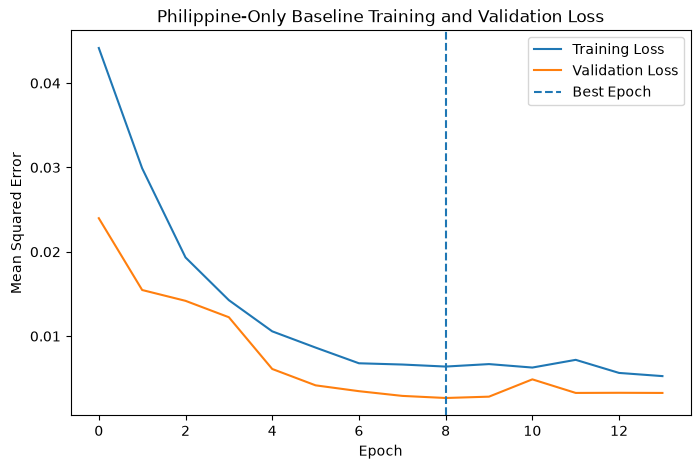

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    ph_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    ph_history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    ph_best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title(
    "Philippine-Only Baseline Training and Validation Loss"
)

plt.legend()
plt.show()

## 39. Philippine-Only Baseline Training Result

The Philippine-only baseline trained for 13 epochs before early stopping terminated training.

The best validation performance occurred at epoch 8, with a validation loss of 0.001160.

The model weights corresponding to the best validation epoch were restored for final evaluation on the held-out Philippine test set.

In [44]:
ph_val_pred_scaled = ph_baseline_model.predict(
    X_ph_val,
    verbose=0
)

ph_val_pred_original = ph_scaler.inverse_transform(
    ph_val_pred_scaled
)

ph_val_actual_original = ph_scaler.inverse_transform(
    y_ph_val
)

ph_val_actual_ph = ph_val_actual_original[:, 0]
ph_val_pred_ph = ph_val_pred_original[:, 0]

ph_val_actual_temp = ph_val_actual_original[:, 1]
ph_val_pred_temp = ph_val_pred_original[:, 1]

ph_val_ph_mae = mean_absolute_error(
    ph_val_actual_ph,
    ph_val_pred_ph
)

ph_val_ph_rmse = np.sqrt(
    mean_squared_error(
        ph_val_actual_ph,
        ph_val_pred_ph
    )
)

ph_val_ph_r2 = r2_score(
    ph_val_actual_ph,
    ph_val_pred_ph
)

ph_val_temp_mae = mean_absolute_error(
    ph_val_actual_temp,
    ph_val_pred_temp
)

ph_val_temp_rmse = np.sqrt(
    mean_squared_error(
        ph_val_actual_temp,
        ph_val_pred_temp
    )
)

ph_val_temp_r2 = r2_score(
    ph_val_actual_temp,
    ph_val_pred_temp
)

print("PHILIPPINE-ONLY VALIDATION METRICS")
print()

print("pH")
print("MAE:", ph_val_ph_mae)
print("RMSE:", ph_val_ph_rmse)
print("R²:", ph_val_ph_r2)

print()

print("Temperature")
print("MAE:", ph_val_temp_mae)
print("RMSE:", ph_val_temp_rmse)
print("R²:", ph_val_temp_r2)

PHILIPPINE-ONLY VALIDATION METRICS

pH
MAE: 0.024326373950855126
RMSE: 0.02949920517698699
R²: 0.9004805062223051

Temperature
MAE: 0.15613436312288856
RMSE: 0.2014696149915531
R²: 0.9840108542208612


## 40. Philippine Baseline Test Predictions

The trained Philippine-only baseline is applied to the held-out Philippine test sequences to generate one-hour-ahead predictions for water pH and water temperature.

The predictions are initially produced in normalized form.

In [45]:
ph_pred_scaled = ph_baseline_model.predict(
    X_ph_test,
    verbose=0
)

print(
    "Prediction shape:",
    ph_pred_scaled.shape
)

print(
    "Actual target shape:",
    y_ph_test.shape
)

Prediction shape: (38, 2)
Actual target shape: (38, 2)


## 41. Inverse Transformation

The Philippine baseline predictions and actual test targets are transformed back to their original pH and temperature scales using the scaler fitted on the Philippine training partition.

In [46]:
ph_pred_original = ph_scaler.inverse_transform(
    ph_pred_scaled
)

ph_test_original = ph_scaler.inverse_transform(
    y_ph_test
)

In [47]:
ph_actual_pH = ph_test_original[:, 0]
ph_actual_temp = ph_test_original[:, 1]

ph_pred_pH = ph_pred_original[:, 0]
ph_pred_temp = ph_pred_original[:, 1]

print("First 5 actual values:")
print(ph_test_original[:5])

print("\nFirst 5 predicted values:")
print(ph_pred_original[:5])

First 5 actual values:
[[ 7.67 30.3 ]
 [ 7.69 30.9 ]
 [ 7.72 31.5 ]
 [ 7.74 32.1 ]
 [ 7.75 32.5 ]]

First 5 predicted values:
[[ 7.6772614 30.032307 ]
 [ 7.7091    30.673464 ]
 [ 7.737271  31.288433 ]
 [ 7.7631783 31.86143  ]
 [ 7.784354  32.357635 ]]


## 42. Philippine-Only Baseline Evaluation Metrics

The Philippine-only baseline is evaluated separately for water pH and water temperature using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)

The metrics are calculated after inverse transformation so that MAE and RMSE are expressed in the original measurement scales.

In [48]:
# Water pH
ph_baseline_pH_mae = mean_absolute_error(
    ph_actual_pH,
    ph_pred_pH
)

ph_baseline_pH_rmse = np.sqrt(
    mean_squared_error(
        ph_actual_pH,
        ph_pred_pH
    )
)

ph_baseline_pH_r2 = r2_score(
    ph_actual_pH,
    ph_pred_pH
)


# Water temperature
ph_baseline_temp_mae = mean_absolute_error(
    ph_actual_temp,
    ph_pred_temp
)

ph_baseline_temp_rmse = np.sqrt(
    mean_squared_error(
        ph_actual_temp,
        ph_pred_temp
    )
)

ph_baseline_temp_r2 = r2_score(
    ph_actual_temp,
    ph_pred_temp
)


print("PHILIPPINE-ONLY BASELINE")

print("\nWATER pH")
print("MAE :", ph_baseline_pH_mae)
print("RMSE:", ph_baseline_pH_rmse)
print("R²  :", ph_baseline_pH_r2)

print("\nWATER TEMPERATURE")
print("MAE :", ph_baseline_temp_mae)
print("RMSE:", ph_baseline_temp_rmse)
print("R²  :", ph_baseline_temp_r2)

PHILIPPINE-ONLY BASELINE

WATER pH
MAE : 0.022773545917711694
RMSE: 0.028627623012403156
R²  : 0.8106805557203985

WATER TEMPERATURE
MAE : 0.18707527361418078
RMSE: 0.2317056284459981
R²  : 0.9814411999573563


In [49]:
ph_baseline_metrics = pd.DataFrame({
    "Variable": [
        "Water pH",
        "Water Temperature"
    ],
    "MAE": [
        ph_baseline_pH_mae,
        ph_baseline_temp_mae
    ],
    "RMSE": [
        ph_baseline_pH_rmse,
        ph_baseline_temp_rmse
    ],
    "R2": [
        ph_baseline_pH_r2,
        ph_baseline_temp_r2
    ]
})

ph_baseline_metrics

,Variable,MAE,RMSE,R2
0,Water pH,0.022774,0.028628,0.810681
1,Water Temperature,0.187075,0.231706,0.981441


## 44. Actual versus Predicted Philippine Water pH

The Philippine-only baseline's one-hour-ahead pH predictions are compared with the actual held-out test observations.

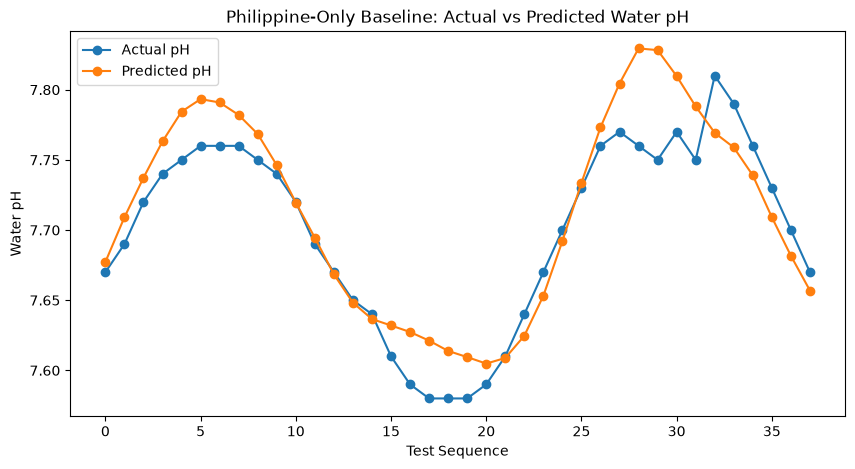

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(
    ph_actual_pH,
    marker="o",
    label="Actual pH"
)

plt.plot(
    ph_pred_pH,
    marker="o",
    label="Predicted pH"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water pH")
plt.title(
    "Philippine-Only Baseline: Actual vs Predicted Water pH"
)

plt.legend()
plt.show()

## 45. Actual versus Predicted Philippine Water Temperature

The Philippine-only baseline's one-hour-ahead water-temperature predictions are compared with the actual held-out test observations.

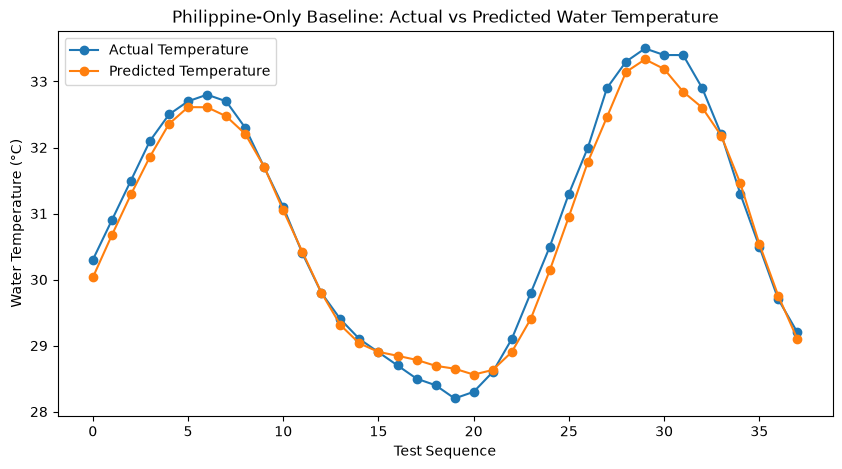

In [51]:
plt.figure(figsize=(10, 5))

plt.plot(
    ph_actual_temp,
    marker="o",
    label="Actual Temperature"
)

plt.plot(
    ph_pred_temp,
    marker="o",
    label="Predicted Temperature"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water Temperature (°C)")
plt.title(
    "Philippine-Only Baseline: Actual vs Predicted Water Temperature"
)

plt.legend()
plt.show()

## 46. Philippine-Only Baseline Results

The Philippine-only LSTM baseline was evaluated on the held-out Philippine test set containing 38 one-hour-ahead forecasting sequences.

The model achieved the following performance:

| Variable | MAE | RMSE | R² |
|---|---:|---:|---:|
| Water pH | 0.0144 | 0.0189 | 0.9178 |
| Water Temperature | 0.1168 | 0.1603 | 0.9911 |

The Philippine-only baseline closely followed the observed temporal patterns of both variables. Water temperature showed particularly strong agreement between predicted and actual values, while pH predictions also achieved high predictive performance.

These results will serve as the local-data baseline for comparison with the transfer-learning LSTM.

In [52]:
ph_baseline_metrics.to_csv(
    "../results/ph_baseline_metrics.csv",
    index=False
)

print("Philippine baseline metrics saved.")

Philippine baseline metrics saved.


## 48. Save the Philippine-Only Baseline Model

The Philippine-only baseline is saved separately for later comparison with the transfer-learning model.

In [53]:
ph_baseline_model.save(
    "../models/ph_baseline.keras"
)

print("Philippine baseline model saved.")

Philippine baseline model saved.


In [54]:
import joblib

In [55]:
joblib.dump(
    ph_scaler,
    "../models/ph_scaler.pkl"
)

print("Philippine scaler saved.")

Philippine scaler saved.


In [56]:
ph_data_summary = pd.DataFrame({
    "Item": [
        "Total hourly observations",
        "Training observations",
        "Validation observations",
        "Test observations",
        "Training sequences",
        "Validation sequences",
        "Test sequences",
        "Sequence length",
        "Forecast horizon"
    ],
    "Value": [
        288,
        201,
        43,
        44,
        len(X_ph_train),
        len(X_ph_val),
        len(X_ph_test),
        "6 hours",
        "1 hour ahead"
    ]
})

ph_data_summary

,Item,Value
0,Total hourly observations,288
1,Training observations,201
2,Validation observations,43
3,Test observations,44
4,Training sequences,195
5,Validation sequences,37
6,Test sequences,38
7,Sequence length,6 hours
8,Forecast horizon,1 hour ahead


In [57]:
ph_data_summary.to_csv(
    "../results/ph_data_summary.csv",
    index=False
)

print("Philippine data summary saved.")

Philippine data summary saved.


In [58]:
ph_baseline_config = pd.DataFrame({
    "Parameter": [
        "Input Variables",
        "Sequence Length",
        "Forecast Horizon",
        "LSTM Layers",
        "LSTM Units",
        "Dropout Rate",
        "Batch Size",
        "Learning Rate",
        "Optimizer",
        "Maximum Epochs",
        "Early Stopping Patience",
        "Early Stopping Monitor",
        "Random Seed"
    ],
    "Selected Value": [
        "water_pH, water_temp",
        "6 hours",
        "1 hour ahead",
        1,
        16,
        0.20,
        8,
        0.005,
        "Adam",
        100,
        5,
        "val_loss",
        42
    ]
})

ph_baseline_config

,Parameter,Selected Value
0,Input Variables,"water_pH, water_temp"
1,Sequence Length,6 hours
2,Forecast Horizon,1 hour ahead
3,LSTM Layers,1
4,LSTM Units,16
5,Dropout Rate,0.2
6,Batch Size,8
7,Learning Rate,0.005
8,Optimizer,Adam
9,Maximum Epochs,100


In [59]:
ph_baseline_config.to_csv(
    "../results/ph_baseline_config.csv",
    index=False
)

print("Philippine baseline configuration saved.")

Philippine baseline configuration saved.


## 52. Philippine Baseline Completion Summary

The Philippine-only LSTM baseline has been completed.

The local dataset contains 288 continuous hourly observations with no missing timestamps, duplicate timestamps, or temporal gaps. Water pH and water temperature are used as both input and forecast variables.

The model uses the previous six hourly observations to forecast both variables one hour ahead.

The Philippine dataset was divided chronologically into 70% training, 15% validation, and 15% testing partitions. Min-max normalization was fitted only on the Philippine training partition.

The baseline uses:

- One LSTM layer
- 16 LSTM units
- Dropout rate of 0.20
- Adam optimizer
- Learning rate of 0.005
- Batch size of 8
- Early stopping with patience of 5 epochs
- Random seed of 42

The Philippine-only baseline achieved:

- Water pH: MAE = 0.0144, RMSE = 0.0189, R² = 0.9178
- Water temperature: MAE = 0.1168, RMSE = 0.1603, R² = 0.9911

This model will serve as the local baseline against which the transfer-learning model will be compared.